In [1]:
# !pip install pandas numpy

In [2]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

def get_df_acc_by_thr_zai(dir_p: Path | str, suffix: str) -> pd.DataFrame:
    # Configuration
    base_dir = Path(dir_p)
    target_keys = np.linspace(0.05, 0.8, 16)  # [0.05 * (i + 1) for i in range(10)]

    data_dict = {}
    # Iterate through all .json files in the directory
    for config_file in sorted(base_dir.glob('*.json')):
        with open(config_file, 'r') as f:
            raw_dict = json.load(f)
            
        # 1) Extract first list element and convert keys/values to float
        float_dict = {}
        for k, v in raw_dict.items():
            try:
                # v is expected to be a list like ["1.23", "ignored_string"]
                float_dict[round(float(k), 4)] = float(v[0])
            except (ValueError, IndexError, TypeError):
                # Safely handle malformed entries or missing list items
                float_dict[round(float(k), 4)] = None
                
        # 2) Extract values for the target keys
        # .get() returns None for missing keys → becomes NaN in the DataFrame
        data_dict[config_file.stem] = [float_dict.get(round(k, 4)) for k in target_keys]

    # 3) Create DataFrame: target keys as index, config names as columns
    df = pd.DataFrame(data_dict, index=[str(round(k, 2)) + '_' + suffix for k in target_keys])
    df.index.name = 'Key'
    return df

def get_df_acc_by_thr_kha(dir_p: Path | str, config_name: str, suffix: str) -> pd.DataFrame:
    # Configuration
    base_dir = Path(dir_p)
    target_keys = np.linspace(0.05, 0.8, 16)  # [0.05 * (i + 1) for i in range(10)]

    data_dict = {}

    # Iterate through each subfolder in the base directory
    for subfolder in sorted(base_dir.iterdir()):
        if subfolder.is_dir():
            json_path = subfolder / config_name
            if json_path.exists():
                with open(json_path, 'r') as f:
                    raw_dict = json.load(f)
                
                # 1) Convert string keys & values to floats
                float_dict = {round(float(k), 4): float(v) for k, v in raw_dict.items()}
                
                # 2) Extract values for the target keys
                # .get() safely returns None if a key is missing (will become NaN in DataFrame)
                data_dict[subfolder.name] = [float_dict.get(round(k, 4)) for k in target_keys]

    # 3) Create DataFrame: target keys as index, subfolder names as columns
    df = pd.DataFrame(data_dict, index=[str(round(k, 2)) + '_' + suffix for k in target_keys])
    df.index.name = 'Key'
    return df

In [3]:
mapper_zai = {
    "one_net": "Single model",
    "CE_std": "Prediction variance",
    "TV_CE_p(1-p)_sum_CE_var": "Total variance, base",
    "TV_pred_exps_p(1-p)_sum_CE_var": "Total variance, CAE (ours)",
    "TV_gt_exps_p(1-p)_sum_CE_var": "Total variance, experts (ours)",
    "test_augmentations": "Test-time augmentations",
    "entropy_CE_sum_CE": "Entropy and MI",
    "mc_dropout": "MC Dropout",
    "huq": "HUQ"
}

mapper_kha = {
    "single_net": "Single model",
    "prediction_variance": "Prediction variance",
    "tv_base": "Total variance, base",
    "tv_cae": "Total variance, CAE (ours)",
    "tv_experts": "Total variance, experts (ours)",
    "mcmc": "MCMC",
    "abnn": "ABNN"
}

In [4]:
def change_df(df: pd.DataFrame, mapper: dict[str, str]) -> pd.DataFrame:
    for name in df.columns:
        if name not in mapper:
            df = df.drop(name, axis=1)
    df = df.rename(mapper, axis=1)
    return df

In [5]:
import json
import pandas as pd
from pathlib import Path

df_1 = get_df_acc_by_thr_kha(
    '/beta/students/khalin/confidence-aware-uncertainty/segmentation/rcs/e3_10k_microavg',
    'rejection_curve_1.json',
    'riga'
)
df_2 = get_df_acc_by_thr_kha(
    '/beta/students/khalin/confidence-aware-uncertainty/segmentation/rcs/e1_lidc_10k_microavg',
    'rejection_curve.json',
    'lidc'
)
df_3 = get_df_acc_by_thr_zai(
    '/beta/students/khalin/uncertainty-nlp-2/uncertainty_estimation/results/bert_v2/rejection_curves_data',
    'pmqa'
)
df_4 = get_df_acc_by_thr_zai(
    '/beta/students/khalin/uncertainty-nlp-2/uncertainty_estimation/results/bloodywell/rejection_curves',
    'bw'
)

df_1 = change_df(df_1, mapper_kha)
df_2 = change_df(df_2, mapper_kha)
df_3 = change_df(df_3, mapper_zai)
df_4 = change_df(df_4, mapper_zai)

df = pd.concat([df_1, df_2, df_3, df_4])

df

,ABNN,MCMC,Prediction variance,Single model,"Total variance, base","Total variance, CAE (ours)","Total variance, experts (ours)",Entropy and MI,HUQ,MC Dropout,Test-time augmentations
Key,,,,,,,,,,,
0.05_riga,0.899957,0.923518,0.932011,0.922719,0.934058,0.930380,0.917688,NaN,NaN,NaN,NaN
0.1_riga,0.934802,0.952100,0.969615,0.952416,0.971233,0.970250,0.973193,NaN,NaN,NaN,NaN
0.15_riga,0.959391,0.961521,0.985434,0.960662,0.984967,0.987607,0.995388,NaN,NaN,NaN,NaN
0.2_riga,0.974322,0.966556,0.991523,0.962664,0.988120,0.995116,0.999331,NaN,NaN,NaN,NaN
0.25_riga,0.977543,0.968677,0.993029,0.963493,0.988822,0.998088,0.999807,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
0.6_bw,NaN,NaN,NaN,0.996820,0.998013,1.000000,0.999006,NaN,0.999205,0.996033,0.996522
0.65_bw,NaN,NaN,NaN,0.996934,0.998864,1.000000,0.998864,NaN,0.999659,0.996529,0.996707
0.7_bw,NaN,NaN,NaN,0.996688,0.998675,1.000000,0.998675,NaN,0.999868,0.997025,0.997615


In [6]:
m = df.min(axis=1) - 0.1
print(m)
for i, col in enumerate(df):
    # using i allows for duplicate columns
    # inplace *may* not always work here, so IMO the next line is preferred
    # df.iloc[:, i].fillna(m, inplace=True)
    df.iloc[:, i] = df.iloc[:, i].fillna(m)

Key
0.05_riga    0.799957
0.1_riga     0.834802
0.15_riga    0.859391
0.2_riga     0.862664
0.25_riga    0.863493
               ...   
0.6_bw       0.896033
0.65_bw      0.896529
0.7_bw       0.896688
0.75_bw      0.896661
0.8_bw       0.896820
Length: 64, dtype: float64


Friedman p-value: 0.000000000000


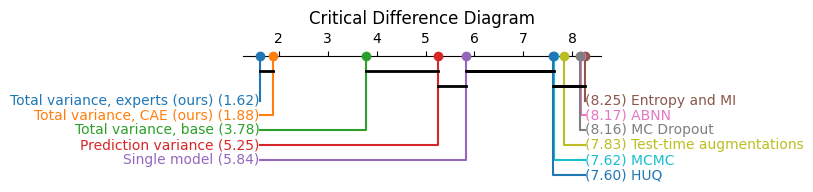

In [7]:
import pandas as pd
import numpy as np
import scikit_posthocs as sp
from scipy.stats import friedmanchisquare
import matplotlib.pyplot as plt

# Your data: rows = datasets, columns = algorithms
# Example DataFrame (performance metric, e.g., accuracy or error)
# df = pd.DataFrame({
#     'alg1': [0.85, 0.78, 0.92, 0.81],  # 4 datasets
#     'alg2': [0.82, 0.80, 0.89, 0.79],
#     'alg3': [0.90, 0.85, 0.94, 0.88],
#     'alg4': [0.75, 0.72, 0.80, 0.70],
# }, index=['ds1', 'ds2', 'ds3', 'ds4'])

# 1. Friedman test (omnibus)
stat, p = friedmanchisquare(*[df[col].values for col in df.columns])
print(f"Friedman p-value: {p:.12f}")

# 2. Post-hoc Nemenyi test
posthoc = sp.posthoc_nemenyi_friedman(df)

# 3. Compute average ranks
ranks = df.rank(axis=1, ascending=False).mean()  # higher = better rank

# 4. Plot CD diagram
plt.figure(figsize=(8, 2))
sp.critical_difference_diagram(
    ranks=ranks,
    sig_matrix=posthoc,
    alpha=0.05,
    label_fmt_left='{label} ({rank:.2f})',
    label_fmt_right='({rank:.2f}) {label}',
)
plt.title("Critical Difference Diagram")
plt.tight_layout()
plt.show()


Friedman Test
----------------------------
Statistic : 390.9974
P-value   : 0.000000

Critical Difference (CD): 1.8871

Average Ranks
----------------------------
Total variance, experts (ours)    1.617188
Total variance, CAE (ours)        1.882812
Total variance, base              3.781250
Prediction variance               5.250000
Single model                      5.835938
HUQ                               7.601562
MCMC                              7.625000
Test-time augmentations           7.828125
MC Dropout                        8.156250
ABNN                              8.171875
Entropy and MI                    8.250000
dtype: float64


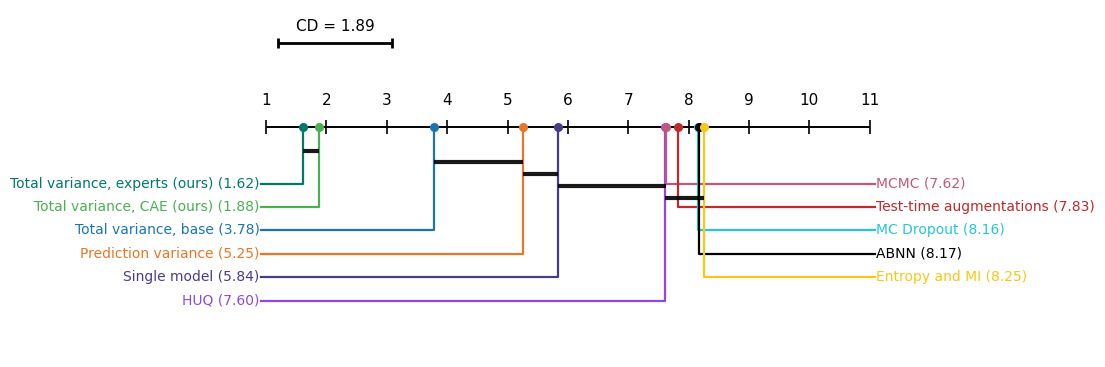

In [13]:
"""
Publication-quality Critical Difference (CD) Diagram
====================================================

This implementation:

- Computes ranks from a pandas.DataFrame
- Runs Friedman + Nemenyi analysis
- Produces a clean CD diagram
- Avoids duplicated significance bars
- Uses compact vertical spacing
- Produces publication-quality figures

Rows   = datasets
Columns = methods
Values = metric values

Example:
    datasets x methods performance matrix

Dependencies:
    pip install numpy pandas matplotlib scipy
"""

from __future__ import annotations

import math
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare
from scipy.stats import rankdata
from scipy.stats import studentized_range


# =============================================================================
# MATPLOTLIB STYLE
# =============================================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.serif": ["Arial"],
    "font.size": 11,
    "axes.linewidth": 1.2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# =============================================================================
# COMPUTE RANKS
# =============================================================================

def compute_average_ranks(
    df: pd.DataFrame,
    higher_is_better: bool = True,
):
    """
    Compute ranks for each dataset.
    """

    ranks = []

    for _, row in df.iterrows():

        vals = row.values.astype(float)

        if higher_is_better:
            r = rankdata(-vals, method="average")
        else:
            r = rankdata(vals, method="average")

        ranks.append(r)

    ranks_df = pd.DataFrame(
        ranks,
        index=df.index,
        columns=df.columns,
    )

    avg_ranks = ranks_df.mean(axis=0)

    return ranks_df, avg_ranks


# =============================================================================
# FRIEDMAN TEST
# =============================================================================

def friedman_test(df):
    arrays = [df[col].values for col in df.columns]
    stat, p = friedmanchisquare(*arrays)
    return stat, p


# =============================================================================
# NEMENYI CD
# =============================================================================

def compute_cd(
    n_methods,
    n_datasets,
    alpha=0.05,
):
    """
    Compute Nemenyi critical difference.
    """

    q_alpha = (
        studentized_range.ppf(
            1 - alpha,
            n_methods,
            np.inf,
        )
        / np.sqrt(2)
    )

    cd = q_alpha * np.sqrt(
        n_methods * (n_methods + 1)
        / (6.0 * n_datasets)
    )

    return cd


# =============================================================================
# FIND MAXIMAL NON-SIGNIFICANT GROUPS
# =============================================================================

def find_maximal_cliques(ranks, cd):
    """
    Find maximal groups where differences <= CD.
    """

    groups = []
    n = len(ranks)

    for i in range(n):

        max_j = i

        for j in range(i + 1, n):

            if ranks[j] - ranks[i] <= cd:
                max_j = j
            else:
                break

        if max_j > i:
            groups.append((i, max_j))

    # Remove redundant groups
    maximal = []

    for g in groups:

        contained = False

        for h in groups:

            if g == h:
                continue

            if g[0] >= h[0] and g[1] <= h[1]:
                contained = True
                break

        if not contained:
            maximal.append(g)

    return maximal


# =============================================================================
# CD DIAGRAM
# =============================================================================

def plot_cd_diagram(
    avg_ranks,
    cd,
    title="Critical Difference Diagram",
    figsize=(11, 3.8),
    save_path=None,
):

    avg_ranks = avg_ranks.sort_values()

    methods = avg_ranks.index.tolist()
    ranks = avg_ranks.values

    n_methods = len(methods)

    # -------------------------------------------------------------------------
    # FIGURE
    # -------------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    ax.axis("off")

    # -------------------------------------------------------------------------
    # AXIS GEOMETRY
    # -------------------------------------------------------------------------

    min_rank = 1
    max_rank = max(
        n_methods,
        int(np.ceil(ranks.max())) + 1,
    )

    axis_y = 1.0

    # -------------------------------------------------------------------------
    # SPLIT LABELS LEFT / RIGHT
    # -------------------------------------------------------------------------

    left_count = math.ceil(n_methods / 2)

    left_methods = methods[:left_count]
    right_methods = methods[left_count:]

    left_ranks = ranks[:left_count]
    right_ranks = ranks[left_count:]

    # -------------------------------------------------------------------------
    # COMPACT LABEL SPACING
    # -------------------------------------------------------------------------

    label_spacing = 0.05

    left_y = [
        axis_y - 0.12 - i * label_spacing
        for i in range(len(left_methods))
    ]

    right_y = [
        axis_y - 0.12 - i * label_spacing
        for i in range(len(right_methods))
    ]

    # -------------------------------------------------------------------------
    # LIMITS
    # -------------------------------------------------------------------------

    lowest_y = min(
        min(left_y) if left_y else axis_y,
        min(right_y) if right_y else axis_y,
    )

    ax.set_xlim(min_rank - 0.8, max_rank + 0.8)
    ax.set_ylim(lowest_y - 0.12, axis_y + 0.25)

    # -------------------------------------------------------------------------
    # MAIN AXIS
    # -------------------------------------------------------------------------

    ax.hlines(
        axis_y,
        min_rank,
        max_rank,
        color="black",
        linewidth=1.4,
    )

    for r in range(min_rank, max_rank + 1):

        ax.vlines(
            r,
            axis_y - 0.015,
            axis_y + 0.015,
            color="black",
            linewidth=1.2,
        )

        ax.text(
            r,
            axis_y + 0.04,
            str(r),
            ha="center",
            va="bottom",
            fontsize=11,
        )

    # -------------------------------------------------------------------------
    # CD BAR
    # -------------------------------------------------------------------------

    cd_x = min_rank + 0.2
    cd_y = axis_y + 0.18

    ax.hlines(
        cd_y,
        cd_x,
        cd_x + cd,
        linewidth=2.0,
        color="black",
    )

    ax.vlines(
        [cd_x, cd_x + cd],
        cd_y - 0.01,
        cd_y + 0.01,
        linewidth=2.0,
        color="black",
    )

    ax.text(
        cd_x + cd / 2,
        cd_y + 0.025,
        f"CD = {cd:.2f}",
        ha="center",
        fontsize=11,
    )

    # -------------------------------------------------------------------------
    # COLORS
    # -------------------------------------------------------------------------

    colors = [
        "#00796B",
        "#4CAF50",
        "#1B75B4",
        "#E67828",
        "#4B3A8C",
        "#9048E1",
        "#C0587E",
        "#BF2A2A",
        "#26C6DA",
        "#000000",
        "#F7C815"
    ]

    # -------------------------------------------------------------------------
    # LEFT SIDE
    # -------------------------------------------------------------------------

    for i, (m, r, y) in enumerate(
        zip(left_methods, left_ranks, left_y)
    ):

        c = colors[i]

        ax.plot(
            r,
            axis_y,
            "o",
            color=c,
            markersize=5.5,
            zorder=3,
        )

        elbow_x = min_rank - 0.08

        ax.plot(
            [r, r, elbow_x],
            [axis_y, y, y],
            color=c,
            linewidth=1.6,
        )

        ax.text(
            elbow_x - 0.03,
            y,
            f"{m} ({r:.2f})",
            ha="right",
            va="center",
            fontsize=10,
            color=c,
        )

    # -------------------------------------------------------------------------
    # RIGHT SIDE
    # -------------------------------------------------------------------------

    for j, (m, r, y) in enumerate(
        zip(right_methods, right_ranks, right_y)
    ):

        idx = j + left_count

        c = colors[idx]

        ax.plot(
            r,
            axis_y,
            "o",
            color=c,
            markersize=5.5,
            zorder=3,
        )

        elbow_x = max_rank + 0.08

        ax.plot(
            [r, r, elbow_x],
            [axis_y, y, y],
            color=c,
            linewidth=1.6,
        )

        ax.text(
            elbow_x + 0.03,
            y,
            f"{m} ({r:.2f})",
            ha="left",
            va="center",
            fontsize=10,
            color=c,
        )

    # -------------------------------------------------------------------------
    # NON-SIGNIFICANT GROUPS
    # -------------------------------------------------------------------------

    groups = find_maximal_cliques(ranks, cd)

    group_y = axis_y - 0.05
    group_step = 0.025

    for i, j in groups:

        ax.hlines(
            group_y,
            ranks[i],
            ranks[j],
            linewidth=3.0,
            color="black",
            alpha=0.9,
        )

        group_y -= group_step

    # -------------------------------------------------------------------------
    # TITLE
    # -------------------------------------------------------------------------

    # ax.set_title(
    #     title,
    #     fontsize=16,
    #     fontweight="semibold",
    #     pad=12,
    # )

    plt.tight_layout()

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=600,
            bbox_inches="tight",
        )

    plt.show()


# =============================================================================
# FULL PIPELINE
# =============================================================================

def critical_difference_pipeline(
    df,
    higher_is_better=True,
    alpha=0.05,
    title="Critical Difference Diagram",
    save_path=None,
):

    # -------------------------------------------------------------------------
    # COMPUTE RANKS
    # -------------------------------------------------------------------------

    ranks_df, avg_ranks = compute_average_ranks(
        df,
        higher_is_better=higher_is_better,
    )

    # -------------------------------------------------------------------------
    # FRIEDMAN TEST
    # -------------------------------------------------------------------------

    stat, p = friedman_test(df)

    print("\nFriedman Test")
    print("----------------------------")
    print(f"Statistic : {stat:.4f}")
    print(f"P-value   : {p:.6f}")

    # -------------------------------------------------------------------------
    # CRITICAL DIFFERENCE
    # -------------------------------------------------------------------------

    cd = compute_cd(
        n_methods=df.shape[1],
        n_datasets=df.shape[0],
        alpha=alpha,
    )

    print(f"\nCritical Difference (CD): {cd:.4f}")

    print("\nAverage Ranks")
    print("----------------------------")
    print(avg_ranks.sort_values())

    # -------------------------------------------------------------------------
    # PLOT
    # -------------------------------------------------------------------------

    plot_cd_diagram(
        avg_ranks=avg_ranks,
        cd=cd,
        title=title,
        save_path=save_path,
    )

    return {
        "ranks_df": ranks_df,
        "avg_ranks": avg_ranks,
        "friedman_statistic": stat,
        "friedman_pvalue": p,
        "cd": cd,
    }


# =============================================================================
# EXAMPLE
# =============================================================================

if __name__ == "__main__":

    # Example:
    # rows = datasets
    # columns = methods

    # df = pd.DataFrame({
    #     "Experts (ours)": [0.91, 0.88, 0.93, 0.90, 0.95],
    #     "CAE (ours)": [0.90, 0.87, 0.91, 0.89, 0.93],
    #     "Base variance": [0.84, 0.82, 0.85, 0.83, 0.86],
    #     "Prediction variance": [0.78, 0.79, 0.80, 0.77, 0.81],
    #     "Single model": [0.76, 0.75, 0.77, 0.74, 0.78],
    #     "HUQ": [0.74, 0.73, 0.75, 0.72, 0.76],
    #     "MCMC": [0.73, 0.72, 0.74, 0.71, 0.75],
    #     "ABNN": [0.72, 0.71, 0.73, 0.70, 0.74],
    #     "MC Dropout": [0.71, 0.70, 0.72, 0.69, 0.73],
    #     "Test-time augmentations": [0.70, 0.69, 0.71, 0.68, 0.72],
    #     "Entropy + MI": [0.69, 0.68, 0.70, 0.67, 0.71],
    # })

    results = critical_difference_pipeline(
        df,
        higher_is_better=True,
        alpha=0.05,
        title="Critical Difference Diagram",
        save_path="cd_diagram.pdf",
    )